# Fase 1 — Selección de datos (KDD)
### Segmentación de caries dentales con SAM 2: construcción del corpus

Este notebook implementa la **Fase 1 (Selección)** del marco KDD descrita en la Sección 3.3.1 del artículo
*"Efecto de un pipeline de preprocesamiento de imágenes intraorales sobre la segmentación de caries dentales condicionada por prompt mediante SAM 2"*.

Resultado: de dos fuentes públicas (DentalAI y Dental Caries de Roboflow Universe, ambas CC BY 4.0) se obtiene un subconjunto de **1069 imágenes** con anotaciones válidas de la clase `Caries` (**Tabla 1** del artículo). La **Fase 2** (`KDD-Fase 2.ipynb`) parte del estado que este notebook guarda al final.

| Sección | Contenido | Artículo |
| --- | --- | --- |
| 2 | Entorno y rutas | 3.2.2 |
| 3 – 4 | Extracción y registro de muestras con su fuente | 3.3.1 |
| 5 | Filtrado semántico (solo `Caries`) | 3.3.1, Fig. 2 |
| 6 | Criterios de inclusión | 3.3.1 |
| 7 | Criterios de exclusión (desenfoque, duplicados, exposición, geometría) | 3.3.1 |
| 8 | Balance de la Fase 1 | Tabla 1 |
| 9 – 10 | Estado para la Fase 2 y paquete de entregables | — |

**Qué hace y qué no hace.** No modifica los píxeles de ninguna imagen, no entrena modelos ni calcula métricas de desempeño.

**Archivos** (carpeta `Fase 1`): `phase1_state.json`, la carpeta `figuras/` y `Fase1_entregables.zip`.

## 2. Configuración del entorno

Se instalan solo las bibliotecas ausentes en Colab y se monta Google Drive **antes** de definir rutas bajo `/content/drive`.

In [1]:
!pip install -q imagehash rarfile pyyaml
# unrar binario requerido por rarfile si alguna fuente se distribuye como .rar
!apt-get install -qq unrar 2>/dev/null || echo

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 28.1 MB/s eta 0:00:00


In [2]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import os
from pathlib import Path
from dataclasses import dataclass
from typing import Optional, Literal, Any

DatasetSource = Literal["dentalai", "roboflow"]

DRIVE = Path("/content/drive/MyDrive")
PROJECT_ROOT = DRIVE / "KDD_Caries"

# Salida de esta ejecución (carpetas "Fase 1" y "Fase 2")
OUTPUT_ROOT = PROJECT_ROOT

# Origen de información previa (opcional)
LEGACY_ROOT = PROJECT_ROOT / "previo"

# Archivos comprimidos originales de cada fuente
DENTALAI_ARCHIVE_CANDIDATES = [PROJECT_ROOT / "datasets_raw" / "Dentalai-Dataset.tar"]
ROBOFLOW_ARCHIVE_CANDIDATES = [PROJECT_ROOT / "datasets_raw" / "Dental-Caries-Roboflow.zip"]


def locate_archive(candidates, patterns):
     """Devuelve el primer archivo existente de `candidates`; si no, busca `patterns`
     dentro de LEGACY_ROOT y de OUTPUT_ROOT."""
     for candidate in candidates:
         if Path(candidate).is_file():
             return Path(candidate)
     for root in (LEGACY_ROOT, OUTPUT_ROOT):
         if root.is_dir():
             for pattern in patterns:
                 hits = sorted(root.rglob(pattern))
                 if hits:
                     return hits[0]
     raise FileNotFoundError(f"No se encontró el archivo comprimido. Rutas probadas: {candidates}")


@dataclass(frozen=True)
class PipelineConfig:
     """Configuración centralizada de rutas y parámetros de la Fase 1."""

     phase_dir: Path = OUTPUT_ROOT / "Fase 1"
     figures_dir: Path = OUTPUT_ROOT / "Fase 1" / "figuras"

     dentalai_archive: str = ""
     roboflow_archive: str = ""

     # Directorios temporales de Colab (no persisten entre sesiones)
     extract_base: Path = Path("/content/datasets/extracted")
     interim_dir: Path = Path("/content/datasets/interim")

     target_class: str = "Caries"

     min_width: int = 640
     min_height: int = 480

     # Umbral calibrado empíricamente (Sección 7.1.1); la fotografía intraoral macro
     # tiene una varianza Laplaciana naturalmente baja frente a fotografía general.
     laplacian_blur_threshold: float = 5.0
     hamming_duplicate_threshold: int = 5

     overexposure_luminance_threshold: int = 240
     overexposure_area_ratio: float = 0.35

     underexposure_luminance_threshold: int = 15
     underexposure_area_ratio: float = 0.35

     uniform_image_std_threshold: float = 3.0


CONFIG = PipelineConfig(
     dentalai_archive=str(locate_archive(DENTALAI_ARCHIVE_CANDIDATES, ["*entalai*.tar", "*entalAI*.tar"])),
     roboflow_archive=str(locate_archive(ROBOFLOW_ARCHIVE_CANDIDATES, ["*oboflow*.zip", "*aries*.zip"])),
)

for path in (CONFIG.phase_dir, CONFIG.figures_dir, CONFIG.extract_base, CONFIG.interim_dir):
     path.mkdir(parents=True, exist_ok=True)

print(f"Salida Fase 1 : {CONFIG.phase_dir}")
print(f"DentalAI (.tar): {CONFIG.dentalai_archive}")
print(f"Roboflow (.zip): {CONFIG.roboflow_archive}")

# FASE 1 — Selección
## 3. Extracción de los datasets

Cada fuente conserva su formato nativo: DentalAI se distribuye como `.tar` (formato Supervisely) y Roboflow como `.zip` (YOLO). La extracción se omite si el destino ya tiene contenido.

In [5]:
import zipfile
import tarfile
import shutil

try:
    import rarfile
    RARFILE_AVAILABLE = True
except ImportError:
    RARFILE_AVAILABLE = False


def _is_already_extracted(dest_dir: Path) -> bool:
    return dest_dir.is_dir() and any(dest_dir.iterdir())


def extract_dataset(archive_path: Path, dest_dir: Path, label: str) -> Path:
    """Extrae un archivo .zip, .rar o .tar en dest_dir, detectando el formato
    a partir de la extensión real del archivo. Omite la extracción si el
    directorio destino ya contiene contenido.
    """
    if not archive_path.is_file():
        raise FileNotFoundError(f"No se encontró el archivo comprimido de {label}: {archive_path}")

    if _is_already_extracted(dest_dir):
        print(f"[{label}] Ya extraído en: {dest_dir} — se omite.")
        return dest_dir

    dest_dir.mkdir(parents=True, exist_ok=True)
    extension = archive_path.suffix.lower()

    try:
        if extension == ".zip":
            with zipfile.ZipFile(archive_path) as archive:
                bad_file = archive.testzip()
                if bad_file is not None:
                    raise zipfile.BadZipFile(f"Archivo corrupto dentro del zip: {bad_file}")
                archive.extractall(dest_dir)

        elif extension == ".tar":
            with tarfile.open(archive_path, "r") as archive:
                archive.extractall(dest_dir)

        elif extension == ".rar":
            if not RARFILE_AVAILABLE:
                raise RuntimeError("rarfile no está disponible para extraer archivos .rar.")
            with rarfile.RarFile(archive_path) as archive:
                archive.extractall(dest_dir)

        else:
            raise ValueError(f"Formato de archivo no soportado para {label}: {extension}")

    except Exception as error:
        shutil.rmtree(dest_dir, ignore_errors=True)
        raise RuntimeError(f"Error extrayendo {archive_path}: {error}") from error

    print(f"[{label}] Extraído ({extension}) -> {dest_dir}")
    return dest_dir


DENTALAI_DIR = extract_dataset(
    Path(CONFIG.dentalai_archive), CONFIG.extract_base / "dentalai", "DentalAI"
)
ROBOFLOW_DIR = extract_dataset(
    Path(CONFIG.roboflow_archive), CONFIG.extract_base / "roboflow", "Roboflow"
)

/tmp/ipykernel_9775/547270778.py:41: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  archive.extractall(dest_dir)


[DentalAI] Extraído (.tar) -> /content/datasets/extracted/dentalai
[Roboflow] Extraído (.zip) -> /content/datasets/extracted/roboflow


## 4. Identificación y preservación de la fuente

Cada muestra se encapsula en un `SampleRecord` con un `sample_id` único (hash del nombre de archivo más la fuente), que garantiza la trazabilidad hasta el origen durante todo el pipeline.

In [6]:
@dataclass
class SampleRecord:
    """Registro que acompaña a cada muestra durante todo el pipeline."""

    sample_id: str
    source: DatasetSource
    original_filename: str
    image_path: Path
    yolo_annotations: list  # lista de (class_id, [x1, y1, x2, y2, ...]) normalizados
    width: Optional[int] = None
    height: Optional[int] = None
    status: str = "pending"
    rejection_reason: Optional[str] = None

    @property
    def num_masks(self) -> int:
        return len(self.yolo_annotations)


def build_sample_id(source: DatasetSource, filename: str) -> str:
    import hashlib
    digest = hashlib.sha1(filename.encode("utf-8")).hexdigest()[:10]
    return f"{source}_{digest}"

## 5. Filtrado semántico por clases

Ambos esquemas se homogeneizan a YOLO de segmentación con clase única `0` (`Caries`). En DentalAI se descartan las demás clases (incluida `Cavity`, porque ninguna fuente documenta un criterio común para distinguir lesión incipiente de cavidad franca). En Roboflow se localiza el índice de `Caries` en `data.yaml`, se reindexa a `0` y se descarta `Tooth`.

### 5.1. DentalAI (anotaciones Supervisely)

In [7]:
import json
import base64
import zlib
import numpy as np
from PIL import Image


def has_target_supervisely(annotation: dict, target_class: str) -> bool:
    return any(obj.get("classTitle") == target_class for obj in annotation.get("objects", []))


def find_image_file(img_dir: Path, ann_filename: str) -> Optional[Path]:
    """Supervisely nombra el .json como '<imagen>.<ext>.json'."""
    base = ann_filename[:-5] if ann_filename.endswith(".json") else ann_filename
    candidate = img_dir / base
    if candidate.is_file():
        return candidate
    stem = Path(base).stem
    for ext in (".jpg", ".jpeg", ".png", ".bmp", ".tiff"):
        candidate = img_dir / f"{stem}{ext}"
        if candidate.is_file():
            return candidate
    return None


def supervisely_polygon_to_yolo(exterior_points: list, img_w: int, img_h: int) -> list:
    coords = []
    for x, y in exterior_points:
        coords.extend([
            max(0.0, min(1.0, x / img_w)),
            max(0.0, min(1.0, y / img_h)),
        ])
    return coords


def supervisely_bitmap_to_yolo_polygon(obj: dict, img_w: int, img_h: int) -> Optional[list]:
    """Aproxima una máscara bitmap Supervisely mediante el rectángulo delimitador
    de sus píxeles activos, expresado como polígono de 4 vértices normalizado.
    """
    try:
        origin = obj.get("origin", [0, 0])
        data_b64 = obj.get("bitmap", {}).get("data", "")
        if not data_b64:
            return None
        raw = zlib.decompress(base64.b64decode(data_b64))
        size = obj.get("bitmap", {}).get("size", {})
        h_bm = size.get("height", int(np.sqrt(len(raw))))
        w_bm = size.get("width", len(raw) // h_bm)
        mask = np.frombuffer(raw, dtype=np.uint8).reshape(h_bm, w_bm)

        rows, cols = np.any(mask, axis=1), np.any(mask, axis=0)
        r_min, r_max = np.where(rows)[0][[0, -1]]
        c_min, c_max = np.where(cols)[0][[0, -1]]

        x0 = (origin[0] + c_min) / img_w
        y0 = (origin[1] + r_min) / img_h
        x1 = (origin[0] + c_max) / img_w
        y1 = (origin[1] + r_max) / img_h
        return [x0, y0, x1, y0, x1, y1, x0, y1]
    except Exception:
        return None


def supervisely_ann_to_yolo(annotation: dict, img_w: int, img_h: int, target_class: str) -> list:
    """Convierte una anotación Supervisely a la lista de tuplas YOLO de destino,
    conservando únicamente los objetos de `target_class`.
    """
    yolo_annotations = []
    for obj in annotation.get("objects", []):
        if obj.get("classTitle") != target_class:
            continue
        geometry_type = obj.get("geometryType", "")

        if geometry_type == "polygon":
            exterior = obj.get("exterior") or obj.get("points", {}).get("exterior", [])
            if len(exterior) >= 3:
                coords = supervisely_polygon_to_yolo(exterior, img_w, img_h)
                if len(coords) >= 6:
                    yolo_annotations.append((0, coords))

        elif geometry_type == "bitmap":
            coords = supervisely_bitmap_to_yolo_polygon(obj, img_w, img_h)
            if coords:
                yolo_annotations.append((0, coords))

        elif geometry_type == "rectangle":
            points = obj.get("exterior") or obj.get("points", {}).get("exterior", [])
            if len(points) >= 2:
                x0 = min(points[0][0], points[1][0]) / img_w
                y0 = min(points[0][1], points[1][1]) / img_h
                x1 = max(points[0][0], points[1][0]) / img_w
                y1 = max(points[0][1], points[1][1]) / img_h
                yolo_annotations.append((0, [x0, y0, x1, y0, x1, y1, x0, y1]))

    return yolo_annotations


def is_valid_image(image_path: Path) -> bool:
    try:
        with Image.open(image_path) as img:
            img.verify()
        return True
    except Exception:
        return False


def build_dentalai_records(dentalai_dir: Path, target_class: str) -> list[SampleRecord]:
    """Recorre los splits de DentalAI, filtra por clase objetivo y convierte
    cada anotación conservada al esquema YOLO de destino.
    """
    meta_path = dentalai_dir / "meta.json"
    with open(meta_path, "r") as handle:
        meta = json.load(handle)
    class_names = [c["title"] for c in meta.get("classes", [])]
    if target_class not in class_names:
        raise ValueError(f"'{target_class}' no está en meta.json de DentalAI. Clases: {class_names}")

    records: list[SampleRecord] = []

    for split in ("train", "valid", "test"):
        ann_dir = dentalai_dir / split / "ann"
        img_dir = dentalai_dir / split / "img"
        if not ann_dir.is_dir():
            continue

        for ann_file in sorted(ann_dir.glob("*.json")):
            with open(ann_file) as handle:
                annotation = json.load(handle)

            if not has_target_supervisely(annotation, target_class):
                continue

            image_path = find_image_file(img_dir, ann_file.name)
            if image_path is None or not is_valid_image(image_path):
                continue

            size = annotation.get("size", {})
            img_w, img_h = size.get("width", 0), size.get("height", 0)
            if not img_w or not img_h:
                with Image.open(image_path) as img:
                    img_w, img_h = img.size

            yolo_annotations = supervisely_ann_to_yolo(annotation, img_w, img_h, target_class)
            if not yolo_annotations:
                continue

            records.append(SampleRecord(
                sample_id=build_sample_id("dentalai", f"{split}_{image_path.name}"),
                source="dentalai",
                original_filename=image_path.name,
                image_path=image_path,
                yolo_annotations=yolo_annotations,
                width=img_w,
                height=img_h,
            ))

    return records


dentalai_records = build_dentalai_records(DENTALAI_DIR, CONFIG.target_class)
print(f"DentalAI: {len(dentalai_records)} muestras con la clase '{CONFIG.target_class}' tras el filtrado semántico.")

DentalAI: 1190 muestras con la clase 'Caries' tras el filtrado semántico.


### 5.2. Roboflow (anotaciones YOLO nativas)

In [8]:
import yaml


def read_yolo_label(label_path: Path) -> list:
    annotations = []
    with open(label_path, "r") as handle:
        for line in handle:
            parts = line.strip().split()
            if not parts:
                continue
            class_id = int(parts[0])
            coords = list(map(float, parts[1:]))
            annotations.append((class_id, coords))
    return annotations


def filter_yolo_label(annotations: list, keep_class_id: int, new_class_id: int = 0) -> list:
    return [(new_class_id, coords) for class_id, coords in annotations if class_id == keep_class_id]


def build_roboflow_records(roboflow_dir: Path, target_class: str) -> list[SampleRecord]:
    """Recorre los splits de Roboflow, localiza dinámicamente el índice de la
    clase objetivo en data.yaml y filtra + reindexa cada etiqueta YOLO.
    """
    with open(roboflow_dir / "data.yaml", "r") as handle:
        roboflow_meta = yaml.safe_load(handle)

    class_names = roboflow_meta.get("names", [])
    if target_class not in class_names:
        raise ValueError(f"'{target_class}' no está en data.yaml de Roboflow. Clases: {class_names}")
    target_class_id = class_names.index(target_class)

    records: list[SampleRecord] = []

    for split in ("train", "valid", "test"):
        img_dir = roboflow_dir / split / "images"
        lbl_dir = roboflow_dir / split / "labels"
        if not img_dir.is_dir() or not lbl_dir.is_dir():
            continue

        image_files = sorted(
            p for p in img_dir.iterdir() if p.suffix.lower() in (".jpg", ".jpeg", ".png")
        )

        for image_path in image_files:
            label_path = lbl_dir / f"{image_path.stem}.txt"
            if not label_path.is_file() or not is_valid_image(image_path):
                continue

            annotations = read_yolo_label(label_path)
            filtered = filter_yolo_label(annotations, keep_class_id=target_class_id, new_class_id=0)
            if not filtered:
                continue

            with Image.open(image_path) as img:
                width, height = img.size

            records.append(SampleRecord(
                sample_id=build_sample_id("roboflow", f"{split}_{image_path.name}"),
                source="roboflow",
                original_filename=image_path.name,
                image_path=image_path,
                yolo_annotations=filtered,
                width=width,
                height=height,
            ))

    return records


roboflow_records = build_roboflow_records(ROBOFLOW_DIR, CONFIG.target_class)
print(f"Roboflow: {len(roboflow_records)} muestras con la clase '{CONFIG.target_class}' tras el filtrado semántico.")

Roboflow: 964 muestras con la clase 'Caries' tras el filtrado semántico.


Conteo tras el filtrado semántico: 1190 imágenes en DentalAI y 964 en Roboflow (2154 candidatas).

In [9]:
initial_counts = {
    "dentalai": len(dentalai_records),
    "roboflow": len(roboflow_records),
}
initial_counts["total"] = sum(initial_counts.values())
print("Conteo tras filtrado semántico, por fuente:", initial_counts)

Conteo tras filtrado semántico, por fuente: {'dentalai': 1190, 'roboflow': 964, 'total': 2154}


### 5.3. Figura: efecto del filtrado semántico (Figura 2 del artículo)

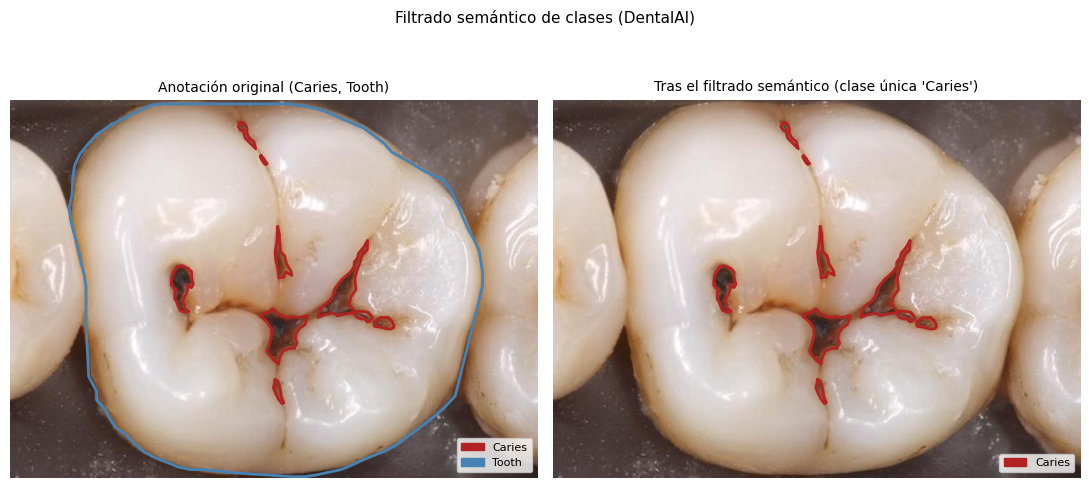

In [30]:
import matplotlib.patches as mpatches
import cv2
import matplotlib.pyplot as plt
import random

CLASS_COLORS = {
    "Tooth": "steelblue",
    "Caries": "firebrick",
    "Crack": "goldenrod",
    "Cavity": "seagreen",
}


def plot_semantic_filtering_example(
    ann_dir: Path,
    img_dir: Path,
    target_class: str,
    save_path: Optional[Path] = None,
) -> None:
    """Busca una anotación Supervisely aleatoria con al menos dos clases distintas
    presentes (incluyendo la clase objetivo) y grafica, lado a lado, el total
    de objetos anotados originalmente y el subconjunto que retiene el filtrado
    semántico de la Sección 5.1.
    """
    suitable_ann_files = []
    for ann_file in sorted(ann_dir.glob("*.json")):
        with open(ann_file) as handle:
            annotation = json.load(handle)

        classes_present = {obj.get("classTitle") for obj in annotation.get("objects", [])}
        if target_class in classes_present and len(classes_present) >= 2:
            image_path = find_image_file(img_dir, ann_file.name)
            if image_path is not None:
                suitable_ann_files.append((ann_file, image_path, annotation, classes_present))

    if not suitable_ann_files:
        print(f"No se encontró ninguna anotación con la clase '{target_class}' y al menos otra clase adicional.")
        return

    # Seleccionar un archivo de anotación aleatorio de los que cumplen los criterios
    ann_file, image_path, annotation, classes_present = random.choice(suitable_ann_files)

    img = cv2.cvtColor(cv2.imread(str(image_path)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]

    fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))

    for ax, keep_only_target, title in zip(
        axes,
        [False, True],
        [f"Anotación original ({', '.join(sorted(classes_present))})",
         f"Tras el filtrado semántico (clase única '{target_class}')"],
    ):
        ax.imshow(img)
        used_labels = set()
        for obj in annotation.get("objects", []):
            class_title = obj.get("classTitle")
            if keep_only_target and class_title != target_class:
                continue
            exterior = obj.get("exterior") or obj.get("points", {}).get("exterior", [])
            if len(exterior) < 3:
                continue
            color = CLASS_COLORS.get(class_title, "orchid")
            xs = [p[0] for p in exterior] + [exterior[0][0]]
            ys = [p[1] for p in exterior] + [exterior[0][1]]
            label = class_title if class_title not in used_labels else None
            used_labels.add(class_title)
            ax.plot(xs, ys, "-", color=color, linewidth=2, label=label)

        ax.set_title(title, fontsize=10)
        ax.axis("off")
        handles = [mpatches.Patch(color=CLASS_COLORS.get(c, "orchid"), label=c) for c in sorted(used_labels)]
        ax.legend(handles=handles, loc="lower right", fontsize=8)

    plt.suptitle("Filtrado semántico de clases (DentalAI)", fontsize=11)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


random.seed(42)  # solo fija la imagen ilustrativa de la figura
plot_semantic_filtering_example(
    DENTALAI_DIR / "train" / "ann",
    DENTALAI_DIR / "train" / "img",
    CONFIG.target_class,
    save_path=CONFIG.figures_dir / "figura_filtrado_semantico.png",
)

## 6. Criterios de inclusión

Descartan de forma temprana archivos no procesables: (i) integridad del archivo (doble validación con Pillow), (ii) resolución mínima de 640×480 px, (iii) homogeneidad del espacio de color (conversión a RGB de tres canales) y (iv) existencia de anotaciones válidas. Solo la resolución genera rechazos en este corpus (447 muestras, todas de DentalAI).

In [11]:
def check_minimum_resolution(record: SampleRecord, config: PipelineConfig) -> bool:
    return record.width >= config.min_width and record.height >= config.min_height

In [12]:
def ensure_rgb(record: SampleRecord, output_dir: Path) -> tuple[bool, bool]:
    try:
        with Image.open(record.image_path) as img:
            if img.mode == "RGB":
                return True, False
            converted = img.convert("RGB")
            output_dir.mkdir(parents=True, exist_ok=True)
            new_path = output_dir / f"{record.sample_id}.jpg"
            converted.save(new_path, quality=95)
            record.image_path = new_path
            return True, True
    except Exception:
        return False, False

In [13]:
def is_image_intact(image_path: Path) -> bool:
    try:
        with Image.open(image_path) as img:
            img.verify()
        with Image.open(image_path) as img:
            img.load()
        return True
    except Exception:
        return False

In [14]:
def has_valid_annotation(record: SampleRecord) -> bool:
    return len(record.yolo_annotations) > 0


def has_one_to_one_correspondence(record: SampleRecord) -> bool:
    return record.image_path.exists()

In [15]:
from collections import defaultdict
from tqdm.notebook import tqdm


def apply_inclusion_criteria(
    records: list[SampleRecord], config: PipelineConfig, rgb_output_dir: Path
) -> tuple[list[SampleRecord], dict[str, int]]:
    counters: dict[str, int] = defaultdict(int)

    for record in tqdm(records, desc="Aplicando criterios de inclusión"):
        if not is_image_intact(record.image_path):
            record.status, record.rejection_reason = "rejected", "archivo_corrupto"
            counters["archivo_corrupto"] += 1
            continue

        if not has_valid_annotation(record):
            record.status, record.rejection_reason = "rejected", "sin_anotacion_valida"
            counters["sin_anotacion_valida"] += 1
            continue

        if not has_one_to_one_correspondence(record):
            record.status, record.rejection_reason = "rejected", "correspondencia_invalida"
            counters["correspondencia_invalida"] += 1
            continue

        if not check_minimum_resolution(record, config):
            record.status, record.rejection_reason = "rejected", "resolucion_insuficiente"
            counters["resolucion_insuficiente"] += 1
            continue

        is_valid, was_converted = ensure_rgb(record, rgb_output_dir)
        if not is_valid:
            record.status, record.rejection_reason = "rejected", "espacio_color_invalido"
            counters["espacio_color_invalido"] += 1
            continue
        if was_converted:
            counters["conversiones_rgb"] += 1

        record.status = "included"

    return records, dict(counters)


dentalai_records, dentalai_inclusion_stats = apply_inclusion_criteria(
    dentalai_records, CONFIG, CONFIG.interim_dir / "dentalai_rgb"
)
roboflow_records, roboflow_inclusion_stats = apply_inclusion_criteria(
    roboflow_records, CONFIG, CONFIG.interim_dir / "roboflow_rgb"
)

Aplicando criterios de inclusión:   0%|          | 0/1190 [00:00<?, ?it/s]

Aplicando criterios de inclusión:   0%|          | 0/964 [00:00<?, ?it/s]

## 7. Criterios de exclusión

Garantizan calidad fotográfica y eliminan redundancia.

### 7.1. Desenfoque severo
Se mide con la varianza del operador Laplaciano sobre la imagen en escala de grises.

In [16]:
import cv2


def compute_laplacian_variance(image_path: Path) -> float:
    image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
    if image is None:
        return 0.0
    return float(cv2.Laplacian(image, cv2.CV_64F).var())


def is_severely_blurred(record: SampleRecord, config: PipelineConfig) -> tuple[bool, float]:
    variance = compute_laplacian_variance(record.image_path)
    return variance < config.laplacian_blur_threshold, variance

#### 7.1.1. Calibración empírica del umbral
El umbral no se tomó de fotografía general: se calibró sobre la distribución de las 1707 imágenes que superaron los criterios de inclusión. El valor **5** marca donde comienza a concentrarse el grupo de imágenes con desenfoque perceptible.

Calibrando umbral de desenfoque:   0%|          | 0/1707 [00:00<?, ?it/s]

Percentiles de varianza Laplaciana (corpus tras criterios de inclusión):
count    1707.00
mean       69.26
std       134.08
min         1.16
1%          2.67
5%          5.55
10%         8.37
25%        18.11
50%        36.43
max      2225.87
dtype: float64


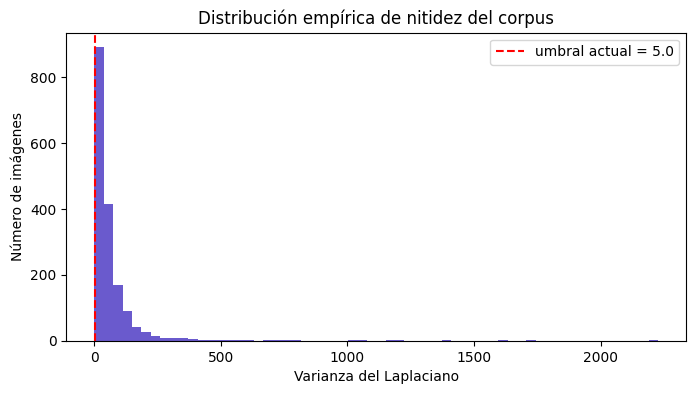


Con el umbral actual (5.0) se rechazarían 71 de 1707 imágenes (4.2%).


In [17]:
import pandas as pd
import matplotlib.pyplot as plt

included_so_far = [r for r in (dentalai_records + roboflow_records) if r.status == "included"]
blur_variances = [compute_laplacian_variance(r.image_path) for r in tqdm(included_so_far, desc="Calibrando umbral de desenfoque")]

blur_series = pd.Series(blur_variances)
print("Percentiles de varianza Laplaciana (corpus tras criterios de inclusión):")
print(blur_series.describe(percentiles=[0.01, 0.05, 0.10, 0.25, 0.50]).round(2))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(blur_series, bins=60, color="slateblue")
ax.axvline(CONFIG.laplacian_blur_threshold, color="red", linestyle="--",
           label=f"umbral actual = {CONFIG.laplacian_blur_threshold}")
ax.set_xlabel("Varianza del Laplaciano")
ax.set_ylabel("Número de imágenes")
ax.set_title("Distribución empírica de nitidez del corpus")
ax.legend()
plt.savefig(CONFIG.figures_dir / "blur_variance_calibration.png", dpi=150)
plt.show()

print(f"\nCon el umbral actual ({CONFIG.laplacian_blur_threshold}) se rechazarían "
      f"{int((blur_series < CONFIG.laplacian_blur_threshold).sum())} de {len(blur_series)} imágenes "
      f"({(blur_series < CONFIG.laplacian_blur_threshold).mean():.1%}).")

#### 7.1.2. Comparación visual: imagen nítida frente a imagen descartada

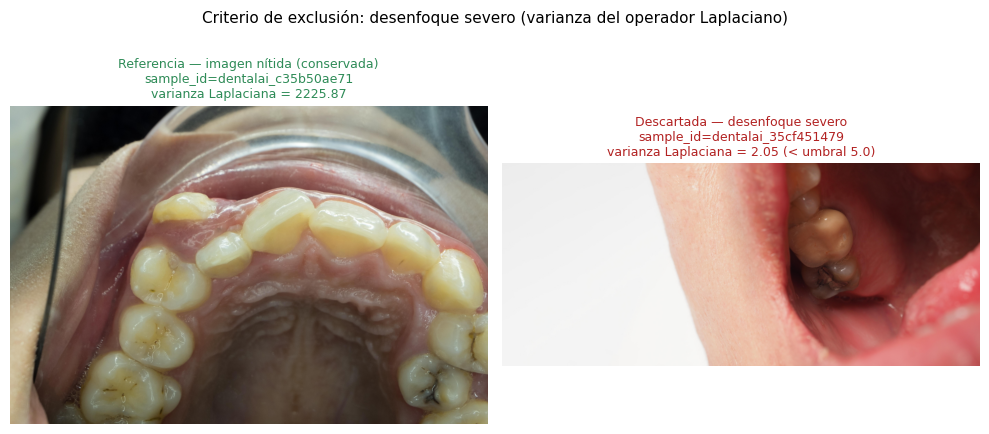

In [18]:
import random
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import cv2
import matplotlib.pyplot as plt

def plot_blur_comparison(
    included_records: list[SampleRecord],
    config: PipelineConfig,
    save_path: Optional[Path] = None,
) -> None:
    """Compara visualmente la imagen más nítida del corpus frente a la
    imagen más desenfocada que fue efectivamente descartada por el criterio
    de la Sección 7.1, anotando la varianza Laplaciana de cada una.
    """
    # Varianza para todo el corpus que llegó a evaluarse (incluidos e incluso
    # los ya marcados 'rejected' por desenfoque, si el registro conserva su ruta)
    scored = [
        (r, compute_laplacian_variance(r.image_path))
        for r in included_records
    ]

    sharpest_record, sharpest_var = max(scored, key=lambda t: t[1])

    blurred_candidates = [
        (r, v) for r, v in scored
        if v < config.laplacian_blur_threshold
    ]
    if not blurred_candidates:
        print("No hay muestras por debajo del umbral en el conjunto proporcionado; "
              "pasa la lista de registros ya marcados 'rejected' por desenfoque.")
        return
    # Select a random blurred image instead of the blurriest one
    blurriest_record, blurriest_var = random.choice(blurred_candidates)

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    for ax, (record, variance), label, color in zip(
        axes,
        [(sharpest_record, sharpest_var), (blurriest_record, blurriest_var)],
        ["Referencia — imagen nítida (conservada)", "Descartada — desenfoque severo"],
        ["seagreen", "firebrick"],
    ):
        img = cv2.cvtColor(cv2.imread(str(record.image_path)), cv2.COLOR_BGR2RGB)
        ax.imshow(img)
        ax.set_title(
            f"{label}\nsample_id={record.sample_id}\nvarianza Laplaciana = {variance:.2f}"
            f"{' (< umbral ' + str(config.laplacian_blur_threshold) + ')' if variance < config.laplacian_blur_threshold else ''}",
            fontsize=9, color=color,
        )
        ax.axis("off")

    plt.suptitle("Criterio de exclusión: desenfoque severo (varianza del operador Laplaciano)",
                 fontsize=11)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


# Se evalúa sobre el corpus que superó los criterios de inclusión (antes de
# aplicar la Sección 7.7 de forma definitiva), para poder mostrar también un
# caso que efectivamente caería bajo el umbral.
random.seed(42)  # solo fija la imagen ilustrativa de la figura
plot_blur_comparison(
    included_so_far, CONFIG,
    save_path=CONFIG.figures_dir / "figura_criterio_desenfoque.png",
)

### 7.2. Duplicados entre y dentro de fuentes
Hash perceptual (pHash) con distancia de Hamming ≤ 5; de cada par se conserva la imagen de mayor resolución. La figura comparativa se genera en 7.7, una vez calculado el registro de duplicados.

In [19]:
import imagehash


def compute_perceptual_hash(image_path: Path) -> imagehash.ImageHash:
    with Image.open(image_path) as img:
        return imagehash.phash(img)


def deduplicate_cross_dataset(
    records: list[SampleRecord], config: PipelineConfig
) -> tuple[list[SampleRecord], list[dict[str, Any]]]:
    duplicate_log: list[dict[str, Any]] = []
    hashes: dict[str, tuple[imagehash.ImageHash, SampleRecord]] = {}

    included = [r for r in records if r.status == "included"]

    for record in tqdm(included, desc="Calculando hashes perceptuales"):
        record_hash = compute_perceptual_hash(record.image_path)
        duplicate_id = None

        for existing_id, (existing_hash, _) in hashes.items():
            if record_hash - existing_hash <= config.hamming_duplicate_threshold:
                duplicate_id = existing_id
                break

        if duplicate_id is None:
            hashes[record.sample_id] = (record_hash, record)
            continue

        existing_hash, existing_record = hashes[duplicate_id]
        current_resolution = record.width * record.height
        existing_resolution = existing_record.width * existing_record.height

        if current_resolution > existing_resolution:
            existing_record.status, existing_record.rejection_reason = "rejected", "duplicado_perceptual"
            del hashes[duplicate_id]
            hashes[record.sample_id] = (record_hash, record)
            kept, removed = record, existing_record
        else:
            record.status, record.rejection_reason = "rejected", "duplicado_perceptual"
            kept, removed = existing_record, record

        duplicate_log.append({
            "kept_sample_id": kept.sample_id, "kept_source": kept.source,
            "removed_sample_id": removed.sample_id, "removed_source": removed.source,
            "hamming_distance": int(record_hash - existing_hash),
        })

    return records, duplicate_log

### 7.3 – 7.6. Exposición, contenido uniforme, relación de aspecto y polígonos
- Sobreexposición: ≥ 35 % del área con luminancia Y ≥ 240 (YCrCb). Subexposición: ≥ 35 % con Y ≤ 15.
- Contenido vacío o uniforme: desviación estándar de luminancia < 3,0.
- Relación de aspecto fuera de [0,2; 5,0].
- Polígonos inválidos: menos de 3 vértices, área nula o coordenadas fuera de [0, 1].

In [20]:
def compute_luminance(image_path: Path) -> np.ndarray:
    image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    return cv2.cvtColor(image, cv2.COLOR_BGR2YCrCb)[:, :, 0]


def is_overexposed(record: SampleRecord, config: PipelineConfig) -> bool:
    luminance = compute_luminance(record.image_path)
    ratio = float(np.mean(luminance >= config.overexposure_luminance_threshold))
    return ratio >= config.overexposure_area_ratio


def is_underexposed(record: SampleRecord, config: PipelineConfig) -> bool:
    luminance = compute_luminance(record.image_path)
    ratio = float(np.mean(luminance <= config.underexposure_luminance_threshold))
    return ratio >= config.underexposure_area_ratio

In [21]:
def is_empty_or_uniform(record: SampleRecord, config: PipelineConfig) -> bool:
    luminance = compute_luminance(record.image_path)
    return float(np.std(luminance)) < config.uniform_image_std_threshold

In [22]:
def has_inconsistent_dimensions(record: SampleRecord) -> bool:
    aspect_ratio = record.width / record.height
    return aspect_ratio < 0.2 or aspect_ratio > 5.0

In [23]:
def polygon_area(points: list[tuple[float, float]]) -> float:
    if len(points) < 3:
        return 0.0
    x = np.array([p[0] for p in points])
    y = np.array([p[1] for p in points])
    return float(0.5 * abs(np.dot(x, np.roll(y, 1)) - np.dot(y, np.roll(x, 1))))


def validate_polygons(record: SampleRecord) -> bool:
    valid_annotations = []
    for class_id, coords in record.yolo_annotations:
        points = [(coords[i], coords[i + 1]) for i in range(0, len(coords), 2)]
        if len(points) < 3:
            continue
        if polygon_area(points) <= 0.0:
            continue
        xs, ys = [p[0] for p in points], [p[1] for p in points]
        if min(xs) < 0 or min(ys) < 0 or max(xs) > 1.0 or max(ys) > 1.0:
            continue
        valid_annotations.append((class_id, coords))

    record.yolo_annotations = valid_annotations
    return len(valid_annotations) > 0

### 7.7. Aplicación consolidada de los criterios de exclusión
Se aplican en orden los criterios de 7.1 a 7.6 y después la deduplicación perceptual.

In [24]:
def apply_exclusion_criteria(
    records: list[SampleRecord], config: PipelineConfig
) -> tuple[list[SampleRecord], dict[str, Any]]:
    stats: dict[str, Any] = defaultdict(int)
    blur_values: list[float] = []

    for record in tqdm(records, desc="Aplicando criterios de exclusión"):
        if record.status != "included":
            continue

        is_blurred, blur_value = is_severely_blurred(record, config)
        blur_values.append(blur_value)
        if is_blurred:
            record.status, record.rejection_reason = "rejected", "desenfoque_severo"
            stats["desenfoque_severo"] += 1
            continue

        if is_overexposed(record, config):
            record.status, record.rejection_reason = "rejected", "sobreexposicion"
            stats["sobreexposicion"] += 1
            continue

        if is_underexposed(record, config):
            record.status, record.rejection_reason = "rejected", "subexposicion_severa"
            stats["subexposicion_severa"] += 1
            continue

        if is_empty_or_uniform(record, config):
            record.status, record.rejection_reason = "rejected", "imagen_vacia_o_uniforme"
            stats["imagen_vacia_o_uniforme"] += 1
            continue

        if has_inconsistent_dimensions(record):
            record.status, record.rejection_reason = "rejected", "dimensiones_inconsistentes"
            stats["dimensiones_inconsistentes"] += 1
            continue

        if not validate_polygons(record):
            record.status, record.rejection_reason = "rejected", "sin_poligonos_validos"
            stats["sin_poligonos_validos"] += 1
            continue

    stats["laplacian_variance_mean"] = float(np.mean(blur_values)) if blur_values else 0.0
    return records, dict(stats)


all_records = dentalai_records + roboflow_records
all_records, exclusion_stats = apply_exclusion_criteria(all_records, CONFIG)
all_records, duplicate_log = deduplicate_cross_dataset(all_records, CONFIG)

Aplicando criterios de exclusión:   0%|          | 0/2154 [00:00<?, ?it/s]

Calculando hashes perceptuales:   0%|          | 0/1633 [00:00<?, ?it/s]

#### Figura: evidencia de duplicación perceptual

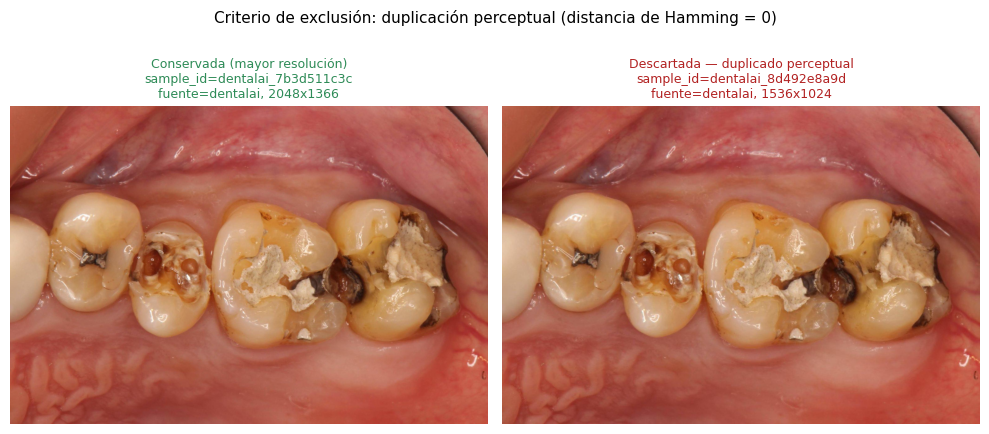

In [25]:
def plot_perceptual_duplicate_example(
    duplicate_log: list[dict[str, Any]],
    all_records: list[SampleRecord],
    save_path: Optional[Path] = None,
) -> None:
    """Muestra un par representativo (kept vs. removed) de la lista de
    duplicados perceptuales cross-dataset detectados en la Sección 7.2,
    anotando la distancia de Hamming entre sus phash y la fuente de cada
    imagen.
    """
    if not duplicate_log:
        print("No se registraron duplicados perceptuales en este corpus.")
        return

    records_by_id = {r.sample_id: r for r in all_records}
    # Se elige el par con menor distancia de Hamming (evidencia más clara).
    example = min(duplicate_log, key=lambda d: d["hamming_distance"])

    kept_record = records_by_id[example["kept_sample_id"]]
    removed_record = records_by_id[example["removed_sample_id"]]

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    for ax, record, label, color in zip(
        axes,
        [kept_record, removed_record],
        ["Conservada (mayor resolución)", "Descartada — duplicado perceptual"],
        ["seagreen", "firebrick"],
    ):
        img = cv2.cvtColor(cv2.imread(str(record.image_path)), cv2.COLOR_BGR2RGB)
        ax.imshow(img)
        ax.set_title(
            f"{label}\nsample_id={record.sample_id}\nfuente={record.source}, "
            f"{record.width}x{record.height}",
            fontsize=9, color=color,
        )
        ax.axis("off")

    plt.suptitle(
        f"Criterio de exclusión: duplicación perceptual (distancia de Hamming = "
        f"{example['hamming_distance']})",
        fontsize=11,
    )
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


plot_perceptual_duplicate_example(
    duplicate_log, all_records,
    save_path=CONFIG.figures_dir / "figura_criterio_duplicacion_perceptual.png",
)

## 8. Balance de la Fase 1 (Tabla 1 del artículo)

Rechazos por criterio y muestras incluidas por fuente. De las 2154 candidatas se rechazan 1085 (50,37 %); la causa principal es la duplicación perceptual (564), seguida de la resolución insuficiente (447) y el desenfoque (71).

In [26]:
final_included = [r for r in all_records if r.status == "included"]

print(f"Total tras filtrado semántico (ambas fuentes): {initial_counts['total']}")
print(f"Total final del corpus tras Fase 1: {len(final_included)}")
print(f"  - DentalAI: {sum(1 for r in final_included if r.source == 'dentalai')}")
print(f"  - Roboflow: {sum(1 for r in final_included if r.source == 'roboflow')}")
print(f"Duplicados perceptuales eliminados (cross-dataset): {len(duplicate_log)}")

Total tras filtrado semántico (ambas fuentes): 2154
Total final del corpus tras Fase 1: 1069
  - DentalAI: 623
  - Roboflow: 446
Duplicados perceptuales eliminados (cross-dataset): 564


In [27]:
from collections import Counter
from IPython.display import display

TABLE1_REASONS = [
    ("Res.", "resolucion_insuficiente"),
    ("Des.", "desenfoque_severo"),
    ("Dup.", "duplicado_perceptual"),
    ("Sobre.", "sobreexposicion"),
    ("Sub.", "subexposicion_severa"),
]


def build_table1(records: list[SampleRecord], initial_counts: dict[str, int]) -> pd.DataFrame:
    """Agrega, por fuente, los rechazos por criterio y las muestras incluidas."""
    known = {key for _, key in TABLE1_REASONS}
    rows = []
    for source, label in (("dentalai", "DentalAI"), ("roboflow", "Roboflow")):
        source_records = [r for r in records if r.source == source]
        reasons = Counter(r.rejection_reason for r in source_records if r.status == "rejected")
        row = {"Fuente": label, "Inic.": initial_counts[source]}
        for column, key in TABLE1_REASONS:
            row[column] = reasons.get(key, 0)
        row["Otros"] = sum(v for k, v in reasons.items() if k not in known)
        row["Incl."] = sum(1 for r in source_records if r.status == "included")
        rows.append(row)
    table = pd.DataFrame(rows)
    total = table.drop(columns="Fuente").sum().to_dict()
    total["Fuente"] = "Total"
    table = pd.concat([table, pd.DataFrame([total])], ignore_index=True)
    return table[["Fuente", "Inic."] + [c for c, _ in TABLE1_REASONS] + ["Otros", "Incl."]]


table1 = build_table1(all_records, initial_counts)
display(table1)

rejected_total = initial_counts["total"] - len(final_included)
print(f"Rechazadas: {rejected_total} de {initial_counts['total']} "
      f"({rejected_total / initial_counts['total']:.2%}); incluidas: {len(final_included)}")

# Verificación contra los valores publicados en el artículo (Tabla 1): solo informa, no detiene la ejecución.
EXPECTED_TABLE1 = {
    "DentalAI": [1190, 447, 70, 48, 1, 1, 623],
    "Roboflow": [964, 0, 1, 516, 0, 1, 446],
    "Total":    [2154, 447, 71, 564, 1, 2, 1069],
}
check_cols = ["Inic.", "Res.", "Des.", "Dup.", "Sobre.", "Sub.", "Incl."]
mismatches = [
    (row["Fuente"], col, int(row[col]), exp)
    for _, row in table1.iterrows()
    for col, exp in zip(check_cols, EXPECTED_TABLE1[row["Fuente"]])
    if int(row[col]) != exp
]
print("Tabla 1: coincide con el artículo." if not mismatches
      else f"AVISO: difieren de la Tabla 1 del artículo (fuente, columna, obtenido, esperado): {mismatches}")

,Fuente,Inic.,Res.,Des.,Dup.,Sobre.,Sub.,Otros,Incl.
0,DentalAI,1190,447,70,48,1,1,0,623
1,Roboflow,964,0,1,516,0,1,0,446
2,Total,2154,447,71,564,1,2,0,1069


Rechazadas: 1085 de 2154 (50.37%); incluidas: 1069
Tabla 1: coincide con el artículo.


## 9. Persistencia del estado para la Fase 2

Se guarda en Drive la lista de registros (rutas, anotaciones, estado y motivo de rechazo) para que la Fase 2 pueda ejecutarse en otra sesión sin repetir la Fase 1. Las rutas de imagen apuntan a `/content/datasets/extracted`, que la Fase 2 vuelve a generar si hace falta.

In [28]:
import json


def record_to_dict(r: SampleRecord) -> dict:
    return {
        "sample_id": r.sample_id, "source": r.source, "original_filename": r.original_filename,
        "image_path": str(r.image_path),
        "yolo_annotations": [[int(c), [float(x) for x in coords]] for c, coords in r.yolo_annotations],
        "width": r.width, "height": r.height,
        "status": r.status, "rejection_reason": r.rejection_reason,
    }


phase1_state = {
    "initial_counts": initial_counts,
    "inclusion_stats": {"dentalai": dentalai_inclusion_stats, "roboflow": roboflow_inclusion_stats},
    "duplicate_log": duplicate_log,
    "records": [record_to_dict(r) for r in all_records],
}

STATE_PATH = CONFIG.phase_dir / "phase1_state.json"
with open(STATE_PATH, "w", encoding="utf-8") as handle:
    json.dump(phase1_state, handle, ensure_ascii=False)

print(f"Estado de la Fase 1 guardado: {STATE_PATH}")
print(f"  registros: {len(phase1_state['records'])} | incluidos: {len(final_included)}")

Estado de la Fase 1 guardado: /content/drive/MyDrive/10mo Semestre/Titulacion II/KDD/Fase 1/phase1_state.json
  registros: 2154 | incluidos: 1069


## 10. Paquete de entregables

Empaqueta el estado y las figuras en un `.zip` dentro de `Fase 1`. Las imágenes no se incluyen.

In [29]:
import zipfile

ZIP_PATH = CONFIG.phase_dir / "Fase1_entregables.zip"
with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as bundle:
    bundle.write(STATE_PATH, STATE_PATH.name)
    for figure_path in sorted(CONFIG.figures_dir.glob("*.png")):
        bundle.write(figure_path, f"figuras/{figure_path.name}")

with zipfile.ZipFile(ZIP_PATH) as bundle:
    for name in bundle.namelist():
        print(" -", name)
print(f"\nPaquete generado: {ZIP_PATH}")

 - phase1_state.json
 - figuras/blur_variance_calibration.png
 - figuras/figura_criterio_desenfoque.png
 - figuras/figura_criterio_duplicacion_perceptual.png
 - figuras/figura_filtrado_semantico.png

Paquete generado: /content/drive/MyDrive/10mo Semestre/Titulacion II/KDD/Fase 1/Fase1_entregables.zip
